# 3 · The event study

Normal returns come from a market model estimated over trading days [-250, -30] before
`t0` (S&P 500 for the US listings, KOSPI for Samsung Electronics). Abnormal returns are
cumulated over the event windows and standardised by the estimation-window residual
volatility (SCAR), which puts Tesla's and Microsoft's reactions on a common scale.

In [1]:
%load_ext autoreload
%autoreload 2
import json
import numpy as np
import pandas as pd
from IPython.display import Image, display
from unpacked_applause.config import FIGURES, PROCESSED, TABLES
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

In [2]:
avg = pd.read_csv(TABLES / "average_effects.csv")
avg[avg["sample"] == "All keynotes"][["window", "n", "mean", "ci_lo", "ci_hi", "p_t", "p_bmp", "pos_share", "p_sign"]]

,window,n,mean,ci_lo,ci_hi,p_t,p_bmp,pos_share,p_sign
0,"[0,0]",343,-0.0002,-0.0031,0.0028,0.8892,0.8265,0.4665,0.6046
1,"[0,+1]",343,0.0001,-0.0039,0.0043,0.9436,0.7503,0.4840,0.8961
2,"[-1,+1]",342,0.0012,-0.0033,0.0057,0.6151,0.4268,0.4912,0.6891
3,"[0,+5]",343,0.0004,-0.0054,0.0064,0.9073,0.9603,0.4694,0.6820
4,"[+2,+20]",340,-0.0057,-0.0154,0.0040,0.2444,0.1465,0.4265,0.0466
5,"[-10,-1]",342,0.0131,0.0076,0.0187,0.0000,0.0001,0.5906,0.0000


In [3]:
avg[avg["window"] == "[0,+1]"][["sample", "n", "mean", "p_t", "p_bmp", "pos_share"]]

,sample,n,mean,p_t,p_bmp,pos_share
1,All keynotes,343,0.0001,0.9436,0.7503,0.4840
7,Audience: live,263,0.0004,0.8732,0.5272,0.4791
13,Audience: hybrid,9,0.0011,0.9569,0.8327,0.6667
19,Audience: virtual,71,-0.0009,0.8220,0.7575,0.4789


In [4]:
pd.read_csv(TABLES / "by_company.csv")[["company", "n", "mean", "ci_lo", "ci_hi", "p_t", "pos_share"]]

,company,n,mean,ci_lo,ci_hi,p_t,pos_share
0,Apple,55,-0.0074,-0.0134,-0.0015,0.0183,0.3636
1,Microsoft,51,0.0024,-0.0026,0.0070,0.3434,0.6275
2,NVIDIA,42,0.0152,0.0003,0.0321,0.0735,0.4762
3,Samsung Electronics,42,0.0024,-0.0036,0.0082,0.4478,0.5476
4,Tesla,40,-0.0216,-0.0380,-0.0052,0.0159,0.3500
5,AMD,38,0.0107,-0.0081,0.0306,0.2977,0.5263
6,Alphabet,34,0.0014,-0.0078,0.0100,0.7633,0.5294
7,Amazon,21,-0.0004,-0.0084,0.0083,0.9337,0.3810
8,Meta Platforms,20,0.0009,-0.0085,0.0103,0.8590,0.5500


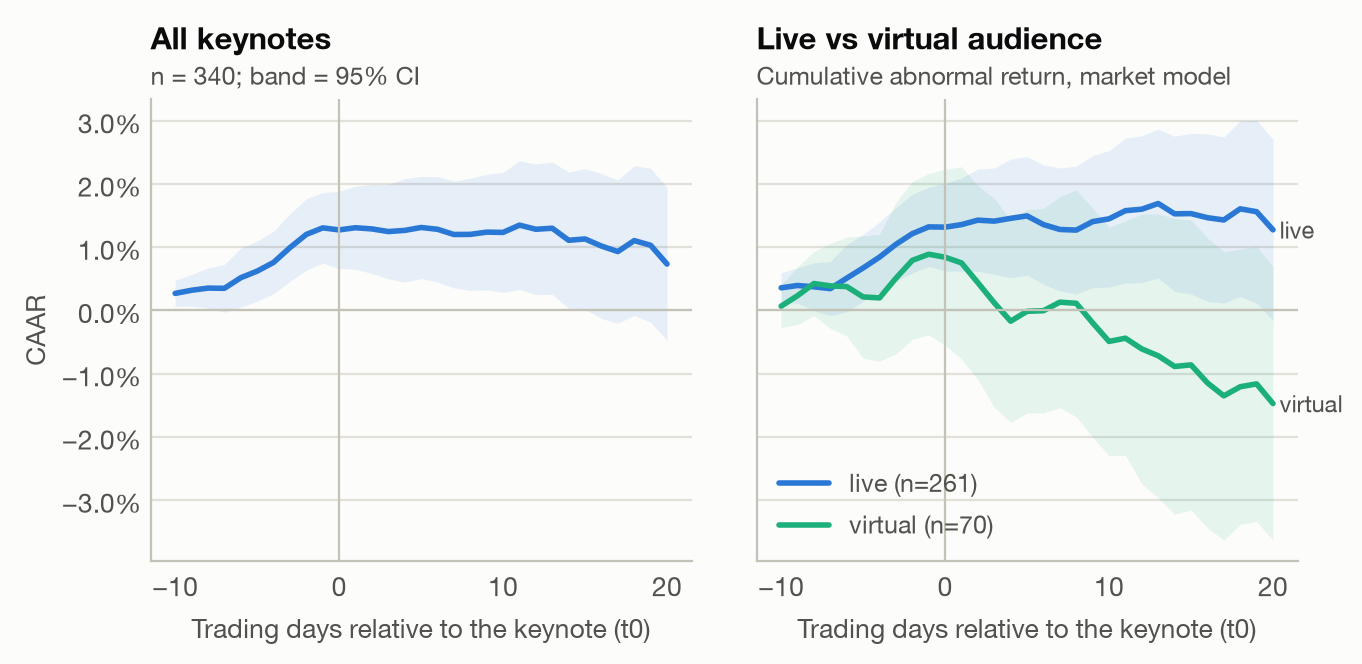

In [5]:
display(Image(filename=str(FIGURES / "caar_paths.png")))

In [6]:
pd.read_csv(TABLES / "live_vs_virtual.csv")

,outcome,live_mean,virtual_mean,diff,p_welch,n_live,n_virtual
0,"SCAR[0,+1]",0.0494,-0.0524,0.1018,0.5857,263,71
1,"|SCAR[0,+1]|",0.9482,1.0792,-0.1310,0.2819,263,71
2,"Abnormal log volume [0,+1] (std.)",0.1942,0.3056,-0.1114,0.4818,263,71
